In [1]:
### Sample networks for each variance plot connectivity

In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [3]:
from Experiment_1.TwoAFCTask import generate_trials
#from Experiment_5.SiegelMillerTask import generate_trials
import networkx as nx
import pandas as pd
import matplotlib
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import seaborn as sns
from Experiment_1.net import *
import os
import numpy as np
import statsmodels.api as sm
import scipy.optimize as opt
import math
#from psychometrics import *
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import networkx as nx
from sklearn.cluster import KMeans
plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE
matplotlib.rcParams['axes.linewidth'] = .75

2afc


In [4]:
df_list = []
for filename in os.listdir('Experiment_1/Results_1'):
    f = os.path.join('Experiment_1/Results_1', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True) 
#original_df = original_df[original_df.mse_z<.035]

In [5]:
def compute_var(variance,n):
    return np.sum(variance[n:])

def compute_p(k, null_k):
    return (np.sum(null_k<k)/len(null_k))

In [6]:
df = original_df.copy()

# Restrict to networks with dim and compute variance above dim
dim = 4
df = df[df.dim == dim]
#df = df[df.k >= dim]
df['var'] = df.variance.apply(lambda x: compute_var(x, dim))
df['k_inertia'] = df.inertia.apply(lambda x: x[dim - 1])
#df['var'] = np.log(df['var'])
df.sort_values('var', ascending=True)

,model_id,w_rec,w_in,w_out,bias,mse_z,weight_decay,threshold,sigma_rec,lambda_std,...,lvar,dim,k,p_value,inertia,activity_std,null_inertia,variance,var,k_inertia
4582,Hsspxe36,"[[0.015599286, -0.012059533, 0.01867535, 0.018...","[[0.029517265, -0.013422065], [-0.053941496, 0...","[[0.09425025, -0.02661038, 0.095872656, 0.1025...","[0.0516731, 0.060223475, 0.0043296805, -0.0081...",0.024672,0.010,0.025,0.0,0.2,...,-0.003162,4,2,0.0,"[0.77756640625, 0.012641805013020833, 0.005555...",0.028600,"[[0.9963738445363479, 0.9849771177594379, 0.96...","[0.7690237, 0.22106464, 0.006608885, 0.0029654...",0.000337,0.001461
1628,l9s4bqgH,"[[0.015643202, 0.015013158, 0.016615894, -0.00...","[[0.0299262, -0.013187597], [0.06356217, -0.06...","[[0.08752385, 0.1168743, 0.07719296, -0.016600...","[0.0488028, 0.066579096, 0.019158801, 0.057191...",0.027431,0.010,0.025,0.0,0.2,...,0.001000,4,2,0.0,"[0.7586453125, 0.015457052951388888, 0.0080782...",0.091692,"[[0.9958586043889184, 0.9841544138050672, 0.94...","[0.7443025, 0.24550664, 0.006148632, 0.0036718...",0.000370,0.001300
4184,myJlKXvw,"[[0.016430408, -0.004610048, -0.0038010275, 0....","[[0.00034433507, 0.014996686], [0.09756347, -0...","[[0.025304394, 0.08682641, 0.08927071, 0.02635...","[0.04234142, 0.030655056, 0.03473632, 0.044201...",0.028268,0.010,0.025,0.0,0.2,...,-0.001000,4,2,0.0,"[0.78680078125, 0.013058921983506944, 0.006372...",0.129996,"[[0.9887971390701258, 0.9773348137437268, 0.99...","[0.7809389, 0.20846027, 0.006851024, 0.0033672...",0.000383,0.001651
801,nhtT0xLD,"[[0.0120731685, 0.012778784, 0.016666528, 0.01...","[[-0.0006348515, 0.01675455], [-0.0020568648, ...","[[0.026570098, 0.027123608, -0.018542495, -0.0...","[0.046708714, 0.046218097, 0.06048006, 0.03364...",0.039702,0.010,0.025,0.0,0.2,...,0.003162,4,2,0.0,"[0.77672421875, 0.013743023003472223, 0.007352...",0.183399,"[[0.9895286341725809, 0.9951185229015709, 0.99...","[0.76416177, 0.22605048, 0.006472072, 0.002931...",0.000384,0.001343
1433,b1NujkFq,"[[0.020939808, -0.026989283, -0.033735286, 0.0...","[[-0.051865313, 0.06522397], [0.0706213, -0.06...","[[-0.021669429, 0.11591687, 0.097422026, 0.025...","[0.05694716, 0.064773954, 0.017238924, 0.04160...",0.025598,0.010,0.025,0.0,0.2,...,0.000000,4,2,0.0,"[0.7938086805555555, 0.011432720269097222, 0.0...",0.056448,"[[0.9969094592945245, 0.9864117301073362, 0.99...","[0.7825993, 0.20721719, 0.006303172, 0.0034913...",0.000389,0.001297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1255,EiR699Bl,"[[0.14619485, 0.063201144, 0.0008567748, -0.06...","[[-0.06630401, -0.055133905], [-0.036380675, -...","[[0.11023466, -0.016088864, -0.08585217, -0.03...","[0.14469256, -0.038123, 0.23515138, 0.03882174...",0.017420,0.005,0.025,0.0,0.2,...,-1.000000,4,6,0.0,"[0.9211341411564626, 0.8391190121882086, 0.781...",0.379719,"[[0.9902937593358949, 0.990823909658171, 0.996...","[0.12261654, 0.101014, 0.08723923, 0.08426298,...",0.604867,0.724452
1253,L58NJoLs,"[[0.33246472, 0.09466045, -0.06274651, -0.1016...","[[-0.009096061, -0.021859815], [0.046178475, -...","[[-0.18583733, -0.06358292, 0.20613477, 0.1931...","[0.2944869, 0.22555992, 0.078153074, 0.0068058...",0.019896,0.005,0.025,0.0,0.2,...,-1.000000,4,6,0.0,"[0.9127239583333333, 0.8415653645833333, 0.780...",0.328629,"[[0.9930353399316333, 0.9926352354831887, 0.98...","[0.11292694, 0.10216284, 0.093445525, 0.085989...",0.605476,0.725663
1262,iHpwiujS,"[[0.13510844, 0.15506412, -0.012042634, -0.026...","[[-0.049467497, 0.011826319], [-0.068963006, 0...","[[-0.17799164, -0.14540048, 0.057880703, -0.03...","[0.08268945, 0.04588861, 0.07098078, 0.0003753...",0.016390,0.005,0.025,0.0,0.2,...,-1.000000,4,6,0.0,"[0.9177857568742985, 0.8469192796015713, 0.778...",0.420316,"[[0.9920615101337388, 0.9933173915047996, 0.99...","[0.10866236, 0.10770383, 0.09239138, 0.0853414...",0.605901,0.728337
1254,AEYiBBQG,"[[0.08593936, 0.04132463, -0.019520137, -0.105...","[[0.0070523005, 0.009542145], [-0.04953

In [45]:
model_ids = ['6jjGVlty','17h0YT0Z','4fTQMP3M','PmexEtJh','gMepSobC','4HMtRPLa','Wsi75Ma6','dwEX3Rpk']

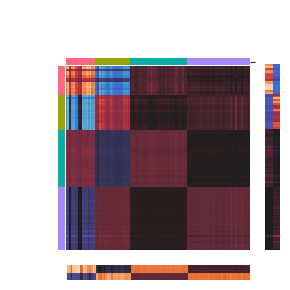

In [7]:
# COMPUTE RESPONSES
model_data = df[df.model_id == 'Hsspxe36']
net = Net(n=100, input_size=2, dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.sigma_in = 0.
net.sigma_rec = 0.
u, z, mask, conditions = generate_trials(
    n_trials=25)

# COMPUTE RESPONSES
x = net(u).detach().cpu().numpy()
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T
#responses = responses[np.mean(responses, axis=1) >.025, ]
responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]


## clustering
k=4
clustering = KMeans(n_clusters=k, n_init=20).fit(responses)

labels = clustering.labels_
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)

sort=np.argsort(clustering.labels_)
w = net.recurrent_layer.weight.data
w_in = net.input_layer.weight.data
w_out = net.output_layer.weight.data
w = w[sort,:]
w = w[:,sort]
w_in = w_in[sort,:]
w_out = w_out[:,sort]

lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)

g = sns.clustermap(pd.DataFrame(w),center=0,row_cluster=False, col_cluster=False, row_colors=row_colors, col_colors=row_colors,figsize=(3,3),cbar_pos=None, xticklabels=False, yticklabels=False)

g.gs.update(left=0.05, right=0.85,bottom=.15)
gs2 = matplotlib.gridspec.GridSpec(1,1, left=.9,top=.77,bottom=.15)
ax2 = g.fig.add_subplot(gs2[0])
sns.heatmap(w_in,ax=ax2,cbar=False,xticklabels=False,yticklabels=False,center=0,)

gs3 = matplotlib.gridspec.GridSpec(1,1,left=.24,top=.1,right=.85)
ax3 = g.fig.add_subplot(gs3[0])
sns.heatmap(w_out,ax=ax3,cbar=False,xticklabels=False,yticklabels=False,center=0,)


g.savefig('Figures/Fig1a.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)